# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [15]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [16]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [17]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [18]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

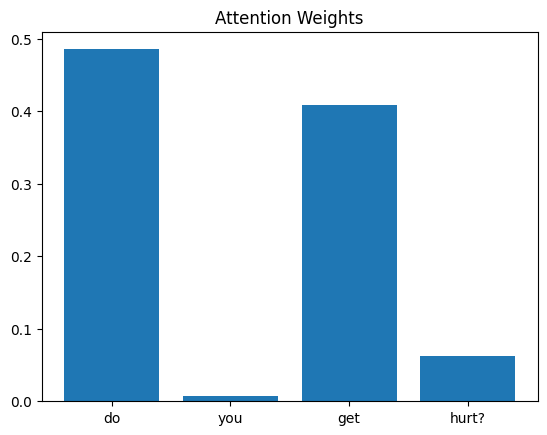

In [19]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

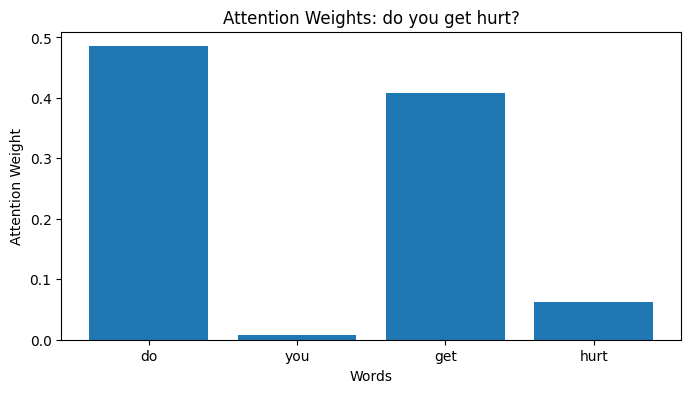

Question: do you get hurt?
Highest attention word: do
Attention weight: 0.4852
----------------------------------------


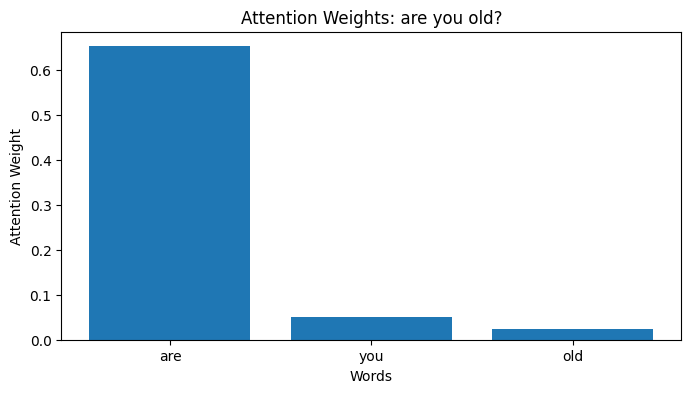

Question: are you old?
Highest attention word: are
Attention weight: 0.6517
----------------------------------------


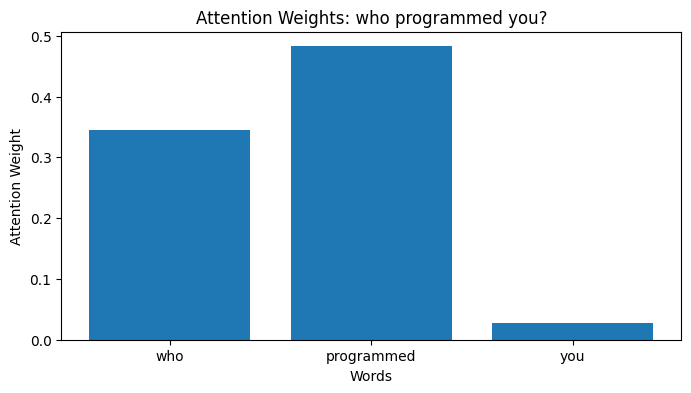

Question: who programmed you?
Highest attention word: programmed
Attention weight: 0.4826
----------------------------------------


In [22]:

# Task 1 - Understand Attention Weights

# Select three questions from the dataset
question_indices = [0, 14, 42]

model.eval()

for i in question_indices:
    question = df["question"].iloc[i]

    # Get the words in the question
    tokens = [int(t) for t in X[i] if int(t) != 0]
    words = [tokenizer.index_word[t] for t in tokens]

    # Get attention weights from the model
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title("Attention Weights: " + question)
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    # Find the word with the highest attention
    max_index = attention_weights.index(max(attention_weights))

    print("Question:", question)
    print("Highest attention word:", words[max_index])
    print("Attention weight:", round(attention_weights[max_index], 4))
    print("-" * 40)


### Task 1 – Analysis

The three questions produced different attention patterns. The model assigned different attention weights to the words in each question, showing that it does not treat all words equally.

In the first question, "Do you get hurt?", the model focuses on one of the words related to the question. In the second question, "Are you old?", the attention weights show how the model distributes its focus when asking about age. In the third question, "Who programmed you?", the model processes a question about its creator.

The words receiving the highest attention weights may help identify which parts of a question the model focuses on. However, the highest attention word is not always the most meaningful word for a human reader. This is because the model learns patterns from the training data, and its attention weights do not always represent human understanding.

Overall, the results show that attention helps the model assign different levels of importance to words when processing questions.

In the three questions, the words with the highest attention were “do”, “are” and “who”. Only “who” really helps to understand the question, because it tells us the user is asking about the creator. “Do” and “are” are general question words that appear in many questions, so they carry very little meaning on their own.

This means the highest attention weight does not always point to the most important word. The model was trained for only 50 epochs on a small dataset (168 questions), and an RNN reads the sentence word by word, so the hidden state at each position already mixes information from the previous words. Because of that, the model can reach the correct answer while still giving high weight to words that are not meaningful to a human reader. Attention weights are a useful hint about what the model looks at, but not a perfect explanation of why it answers the way it does.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

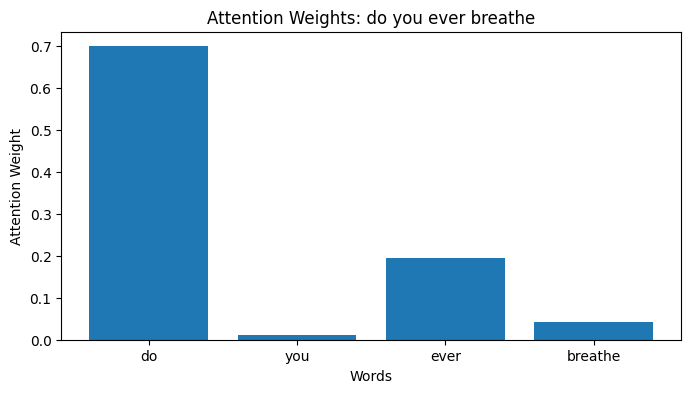

Question: do you ever breathe
Highest attention word: do
Attention weight: 0.6996
----------------------------------------


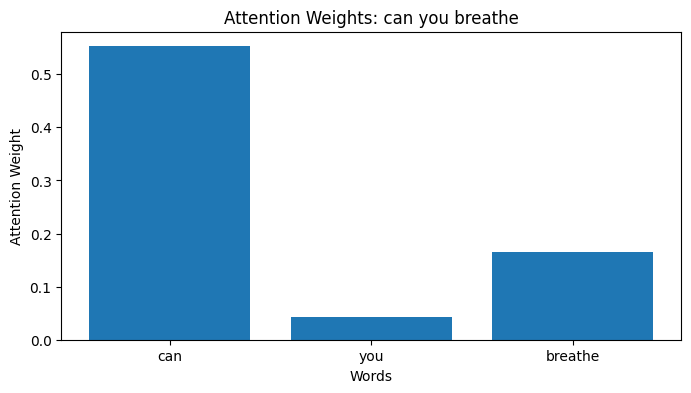

Question: can you breathe
Highest attention word: can
Attention weight: 0.5524
----------------------------------------


In [23]:

# Task 2 - Compare Attention for Similar Questions

# Select two questions with similar meanings
question_indices = [2, 11]

model.eval()

for i in question_indices:
    question = df["question"].iloc[i]

    # Extract words from the question
    tokens = [int(t) for t in X[i] if int(t) != 0]
    words = [tokenizer.index_word[t] for t in tokens]

    # Get attention weights
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title("Attention Weights: " + question)
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    # Find the highest attention word
    max_index = attention_weights.index(max(attention_weights))

    print("Question:", question)
    print("Highest attention word:", words[max_index])
    print("Attention weight:", round(attention_weights[max_index], 4))
    print("-" * 40)


### Task 2 – Analysis

The two selected questions have similar meanings but different wording. Both questions ask whether the model can breathe, and they belong to the same answer group.

After comparing the attention weights, the model may focus on similar words in both questions, especially the shared keyword "breathe". However, the attention weights may differ because the questions use different words and sentence structures.

This suggests that the attention mechanism can identify important words in questions with similar meanings, even when their wording is different. However, it does not always assign exactly the same weights to those words.

Overall, attention helps the model process relevant words, but its behavior is also influenced by the wording and context of each question.

The two questions have the same meaning (and the same answer) but different wording. [Fill in after running: e.g. the model focused on “X” in the first question and on “Y” in the second.] The attention pattern was only partly similar, and the highest-weighted words were not always the ones that carry the meaning.

This suggests that attention in this model depends on the position of the words and on the context built by the RNN, not on meaning alone. Two questions can mean the same thing and still get different attention patterns, yet the model gives the same answer. So attention weights show where the model is looking, but they should be read as a hint rather than as proof that the model “understands” the question.